<a href="https://colab.research.google.com/github/ZixuanYang58/ZixuanYang58-DataScience-GenAI-Submissions/blob/main/Seminars/Week3_Seminar_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic Exploratory Data Analysis with Generative AI

In [1]:

import pandas as pd

from google.colab import files
uploaded = files.upload()

titanic = pd.read_csv("titanic.csv")
titanic.head()


Saving titanic.csv to titanic.csv


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# 1. Display shape
print(f"DataFrame Shape: {titanic.shape}\n")

# 2. Build missing value statistics
missing_count = titanic.isnull().sum()
missing_percentage = (titanic.isnull().sum() / len(titanic)) * 100

# 3. Combine with data types into a summary DataFrame
summary_df = pd.DataFrame({
    'Data Type': titanic.dtypes,
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage.round(2)
})

display(summary_df)

DataFrame Shape: (891, 12)



,Data Type,Missing Count,Missing Percentage (%)
PassengerId,int64,0,0.00
Survived,int64,0,0.00
Pclass,int64,0,0.00
Name,object,0,0.00
Sex,object,0,0.00
Age,float64,177,19.87
SibSp,int64,0,0.00
Parch,int64,0,0.00
Ticket,object,0,0.00
Fare,float64,0,0.00


## 2. Survival Analysis by Sex and Passenger Class

Survival Rate by Sex:


,Sex,Survived
0,female,0.742038
1,male,0.188908



Survival Rate by Passenger Class:


,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


/tmp/ipykernel_1925/3115951667.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=survival_by_sex, ax=axes[0], palette='muted')
/tmp/ipykernel_1925/3115951667.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=survival_by_class, ax=axes[1], palette='deep')


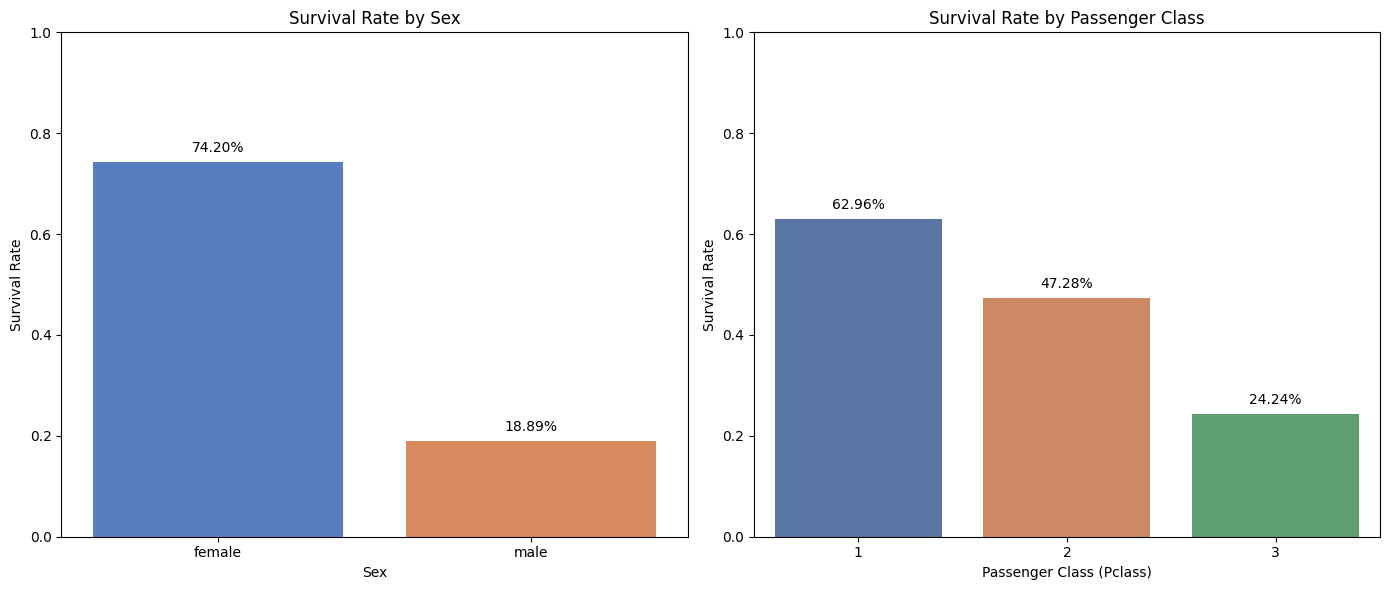

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate survival rates
survival_by_sex = titanic.groupby('Sex')['Survived'].mean().reset_index()
survival_by_class = titanic.groupby('Pclass')['Survived'].mean().reset_index()

print("Survival Rate by Sex:")
display(survival_by_sex)
print("\nSurvival Rate by Passenger Class:")
display(survival_by_class)

# 2. Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart for Survival Rate by Sex
sns.barplot(x='Sex', y='Survived', data=survival_by_sex, ax=axes[0], palette='muted')
axes[0].set_title('Survival Rate by Sex')
axes[0].set_xlabel('Sex')
axes[0].set_ylabel('Survival Rate')
axes[0].set_ylim(0, 1)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha='center')

# Bar chart for Survival Rate by Passenger Class
sns.barplot(x='Pclass', y='Survived', data=survival_by_class, ax=axes[1], palette='deep')
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_xlabel('Passenger Class (Pclass)')
axes[1].set_ylabel('Survival Rate')
axes[1].set_ylim(0, 1)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha='center')

plt.tight_layout()
plt.show()

### Findings – Survival by Sex and Passenger Class

Female passengers had a substantially higher survival rate (74.20%) than male passengers (18.89%).

Survival rates also varied by passenger class: 62.96% for first class, 47.28% for second class, and 24.24% for third class.

These results show associations between survival, sex and passenger class within this dataset, but they do not by themselves establish causation.

## 3. Age and Fare Distributions

Age Summary Statistics:
  - Median: 28.0
  - Minimum: 0.42
  - Maximum: 80.0

Fare Summary Statistics:
  - Median: 14.4542
  - Minimum: 0.0
  - Maximum: 512.3292



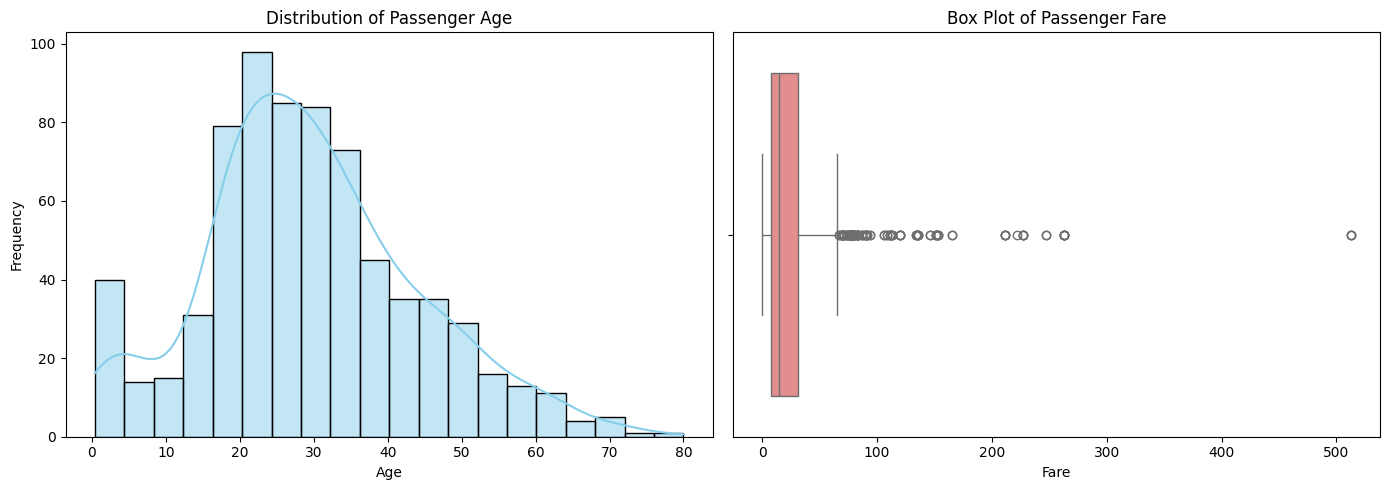

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compute summary statistics (excluding missing values)
age_median = titanic['Age'].median()
age_min = titanic['Age'].min()
age_max = titanic['Age'].max()

fare_median = titanic['Fare'].median()
fare_min = titanic['Fare'].min()
fare_max = titanic['Fare'].max()

print(f"Age Summary Statistics:\n  - Median: {age_median}\n  - Minimum: {age_min}\n  - Maximum: {age_max}\n")
print(f"Fare Summary Statistics:\n  - Median: {fare_median}\n  - Minimum: {fare_min}\n  - Maximum: {fare_max}\n")

# 2. Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of Age
sns.histplot(data=titanic, x='Age', kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Passenger Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Box plot of Fare
sns.boxplot(data=titanic, x='Fare', ax=axes[1], color='lightcoral')
axes[1].set_title('Box Plot of Passenger Fare')
axes[1].set_xlabel('Fare')

plt.tight_layout()
plt.show()

### Findings – Age and Fare Distributions

Passenger ages range from 0.42 to 80 years, with a median of 28 years. The age distribution is concentrated mainly between 20 and 40 years, with some right skewness. However, 177 missing age values limit the completeness of this analysis.

Passenger fares range from 0 to 512.3292, with a median of 14.4542. The fare distribution is strongly right-skewed, with several high-value outliers. These unusual fares should be investigated rather than automatically removed, as they may reflect genuine ticketing differences.

## 4. Overall EDA Findings and Limitations

The Titanic dataset contains 891 passengers and 12 variables. Missing data is primarily concentrated in Cabin (77.10%) and Age (19.87%), with a small number of missing Embarked values (0.22%).

The overall survival rate is approximately 38.38%. Survival rates vary substantially by sex and passenger class. Female passengers and first-class passengers have higher observed survival rates.

Age is concentrated mainly among younger and middle-aged adults, while Fare has a strongly right-skewed distribution with several high-value outliers.

These findings provide useful insights for further analysis, but they are descriptive rather than causal. Missing values, extreme fares and potential relationships between explanatory variables should be considered before building predictive models.

Generative AI was used to help produce the analysis code, and the outputs were checked against the dataset.